
# Assignments #2 Supervised Learning  and Unsupervised learning 

In [2]:
# ---- (Run this first) ----
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import Perceptron, LinearRegression
from sklearn import datasets
from sklearn.neighbors import NearestNeighbors

# letting plots appear inline
%matplotlib inline

print("All Done!") 


All Done!



## Task 1 Theory questions

Answer **in text** below each question. (1-3 lines per answer)

1. What is **supervised learning**? 
2. Define **classification**. Give one example.  
3. Define **regression**. Give one example.
4. Compare the **difference** between classification and regression? 
5. What is a **confusion matrix** used for and how does it help evaluate the performance of a classification model?
6. Why do we **preprocess** data before training? Name **two** techniques.

###  **Response:**
1. Supervised learning is the process of developing/training a machine learning model with labeled data.
2. Classification is the act of placing data into a fixed amount of categories.This would be done for the sake of making the data more efficient to work with. Let's say, for example, that we had a diverse data set of people with different gender, hair color, etc, and we wanted to identify the people with brown eyes. We would essentially train our machine learning model with 2 classes in mind: *has brown eyes*, and *does NOT have brown eyes*.
3. Regression is defined as the correlation/relationship between input and output variables. An example of this could be the comparison between outdoor temperature and ice cream sales. We could observe that there is a relationship between the two, as there would be more ice cream sales during the summer(hotter outside temperature) as opposed to the winter.
4. The main difference between classification and regression lies in the types of outputs we expect. For regression we deal with continuous variables, which lead to an infinite number of possibilites. Mathematically this would be represented as $ -\infty < x < \infty $ (where *x* is the input variable). On the other hand, classification has a fixed number of possibilites, which is based on the classes we've defined.
5. A confusion matrix is a table that's used for assessing the performance of a classification model. It does the evaluation by identifying successful predictions(true positives and negatives) and failed predictions(false negatives and positives). Then, we use a score-based calculation, such as the F1-score, to quantify the model's accuracy. 
6. Preprocessing serves the purpose of transforming raw data into a suitable format for the ML model. We preprocess our data before training because we want to remove noise and gaps from the raw data, that may be incompatible with mathematical algorithms. A common method is binarization, which sets numbers to boolean values. Another method is scaling, which reduces features into suitable ranges so that we can avoid outliers.


## Task 2 Perceptron on a simple problem

We use **Perceptron** for a binary task (a "OR gate" data).

**Steps:**
0. Build small binary dataset `X_or`, `y_or`.
1. Train `Perceptron()` with default params.
2. Print predictions for all inputs.
3. Try different `max_iter` and `eta0` (learning rate).
4. Answer one question.

(Tip: Keep it simple. Focus on input → output mapping.)


In [38]:
# --- Task 2.0: Data (OR problem: output is 1 except when both inputs are 0)
X_or = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_or = np.array([0,1,1,1])


# --- Task 2.1: Train Perceptron 
#     (Hint: use Perceptron() from sklearn.linear_model; then fit(X_or, y_or);
#            use default params first, then try changing max_iter and eta0)

model = Perceptron(max_iter=1000, eta0=1)
model.fit(X_or, y_or)


# --- Task 2.2: Predict
#      (Hint: use clf_perc.predict([x]) for each x in X_or, 
#             where clf_perc is the trained model, replace clf_perc with your model name)

def Result(MODEL):
    accuracy_count = 0
    for i, x in enumerate(X_or):
        predicted = MODEL.predict([x])[0]
        expected = y_or[i]
        IsCorrect = predicted == expected
        accuracy_count += int(IsCorrect)
    
        print("Input: ", x.astype(int))
        print("Result: ", predicted)
        print("Expected: ", expected)
    avg = accuracy_count/(len(X_or))
    print("average accuracy score: ", avg)

Result(model)

# --- Task 2.3: Questions ---
# Q1: Change max_iter and/or eta0 and re-train. Do results change?

model2 = Perceptron(max_iter=200, eta0=5)
model2.fit(X_or, y_or)

model3 = Perceptron(max_iter=3000, eta0=0.1)
model3.fit(X_or, y_or)

model4 = Perceptron(max_iter=1500, eta0=0.01)
model4.fit(X_or, y_or)

print("Model 2: 200 iterations, eta0=5")
Result(model2)

print("Model 3: 3000 iterations, eta0=0.1")
Result(model3)

print("Model 4: 200 iterations, eta0=0.01")
Result(model4)

#  -> (your answer): Through varying iterations and learning rates, the results remain the same

Input:  [0 0]
Result:  0
Expected:  0
Input:  [0 1]
Result:  1
Expected:  1
Input:  [1 0]
Result:  1
Expected:  1
Input:  [1 1]
Result:  1
Expected:  1
average accuracy score:  1.0
Model 2: 200 iterations, eta0=5
Input:  [0 0]
Result:  0
Expected:  0
Input:  [0 1]
Result:  1
Expected:  1
Input:  [1 0]
Result:  1
Expected:  1
Input:  [1 1]
Result:  1
Expected:  1
average accuracy score:  1.0
Model 3: 3000 iterations, eta0=0.1
Input:  [0 0]
Result:  0
Expected:  0
Input:  [0 1]
Result:  1
Expected:  1
Input:  [1 0]
Result:  1
Expected:  1
Input:  [1 1]
Result:  1
Expected:  1
average accuracy score:  1.0
Model 4: 200 iterations, eta0=0.01
Input:  [0 0]
Result:  0
Expected:  0
Input:  [0 1]
Result:  1
Expected:  1
Input:  [1 0]
Result:  1
Expected:  1
Input:  [1 1]
Result:  1
Expected:  1
average accuracy score:  1.0



## Task 3 Linear Regression (Single Variable)

We fit a **Linear Regression** model to a 1D dataset.

**Steps:**
1. Generate synthetic data: `y = 2.5 * x + noise`.
2. Fit `LinearRegression()`.
3. Report **MAE**, **MSE**, **R²**.
4. Plot data points and the regression line.
5. Answer questions 

R2 Score:  0.9820932955693132
Mean Absolute Error:  0.8068378981693897
Mean Squared Error:  1.0116130788906528


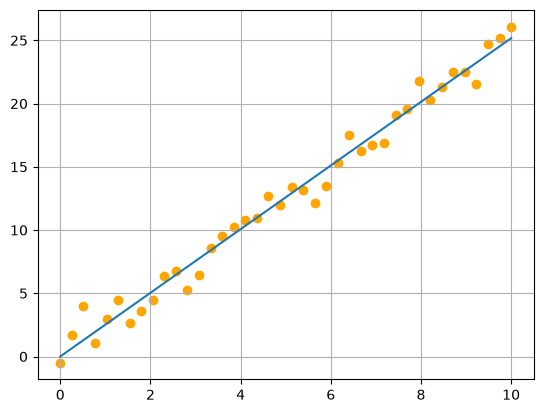

In [39]:
# --- Task 3.1: Generate synthetic single variable data: y = 2.5 * x + noise, noise ~ N(0,1), X in [0,10], 40 samples
#     (Hint: use linspace to generate x values; use np.random.normal to generate noise)

def y(x):
    return 2.5*x + np.random.normal(0, 1, size=40)
    

x_values = np.linspace(0, 10, 40)
data = y(x_values)


# --- Task 3.2: Fit model 
#     (Hint: use LinearRegression() from sklearn.linear_model; then fit())


model = LinearRegression()
model.fit(x_values.reshape(-1, 1), data) #reshaped x_values
y_pred = model.predict(x_values.reshape(-1,1))
truth = data

# --- Task 3.3: Metrics (MAE, MSE, R²)

R2_Score = r2_score(truth, y_pred)
MAE = mean_absolute_error(truth, y_pred)
MSE = mean_squared_error(truth, y_pred)

print("R2 Score: ", R2_Score)
print("Mean Absolute Error: ", MAE)
print("Mean Squared Error: ", MSE)

# --- Task 3.4: Plot data points and the regression line

plt.figure()
plt.scatter(x_values, data, color="orange")
plt.plot(x_values, y_pred)

plt.grid(True)
plt.show()

# --- Task 3.5: Questions ---
# Q1: Change the slope in data generation to 3.0 and re-run. What happens to R^2? 
#  -> (your answer): We can observe that R^2 increases slightly, from 0.9796 to 0.987 in my case.
        # m=2.5, R^2 = 0.9796
        # m=3.0, R^2 = 0.987
# Q2: Try adding larger noise (e.g., std=3.0). How do MAE/MSE change?
#  -> (your answer): The pattern we can observe is that MAE and MSE increase significantly.
# As seen in the images uploaded, the MAE and MSE had large jumps with standard deviations of 1, 3, and 5


## (Final task) Task 4 End-to-End Classification Pipeline

We build a complete supervised learning pipeline using **Digits** data:
- **Aim:** Classify hand-written digits ("0"–"9").
- **Model:** `MLPClassifier`, a simple neural network.
- **Outputs:** Accuracy and **confusion matrix**.

**Steps:**
1. Load data: `datasets.load_digits()`.
2. Train/validation split: 80% / 20%.
3. Scale features with `StandardScaler()`.
4. Train `MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)`.
5. Evaluate on validation set. Print accuracy.
6. Show the **confusion matrix** with `ConfusionMatrixDisplay`.
7. Write 3–5 lines: What mistakes are most common? Why?

**Tips:**
- If training warns about convergence, **increase** `max_iter`.
- Use a **small network** to keep runtime short.


classification score:  0.9777777777777777


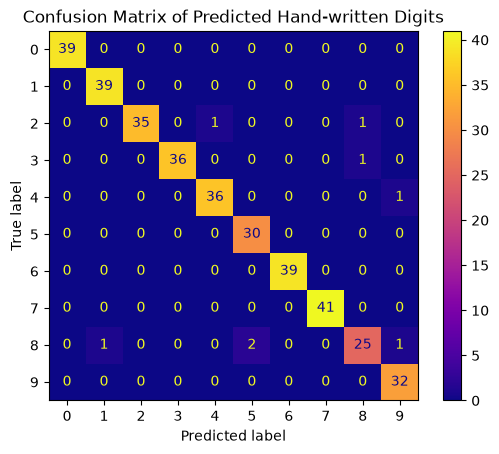

In [32]:
# --- Task 4.1: Load digits
#     (Hint: use datasets.load_digits() from sklearn)

digits = datasets.load_digits()
X = digits.data
Y = digits.target

# --- Task 4.2: Split data into train and validation 
#     (Hint: use train_test_split from sklearn.model_selection)

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, train_size=0.8)

# --- Task 4.3: Scaling (NOTE: fit on training dataset only!!)
#     Important: fit the scaler on the training data ONLY (scaler.fit(X_train) or scaler.fit_transform(X_train)), 
#       which computes the mean/std (or min/max) from training alone. 
#       Then use the same scaler to transform the validation data (scaler.transform(X_val)).
#       Why?:  Because we want to avoid data leakage from the validation set into the training process.

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_test) #transformed validation data

# --- Task 4.4: Train a MLPClassifier
#     (Hint: use MLPClassifier from sklearn.neural_network;  then fit it on the SCALED training data, X_train_scaled, y_train)

classifier = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)
classifier.fit(x_train_scaled, y_train)

# --- Task 4.5: Evaluate.  Print accuracy.
#    (Hint: use mlp.score(X_val_scaled, y_val), where mlp is your trained model.
#           remember to pass the scaled validation data, X_val_scaled, not the original X_val)

score = classifier.score(x_val_scaled, y_test)
print("classification score: ", score)

# --- Task 4.6: Confusion matrix
#    (Hint: use confusion_matrix and ConfusionMatrixDisplay from sklearn.metrics)

y_pred = classifier.predict(x_val_scaled)
matrix = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(matrix,display_labels=digits.target_names)
display.plot(cmap="plasma")

plt.title("Confusion Matrix of Predicted Hand-written Digits")
plt.show()

# --- Task 4.7: Questions ---
# 1: In 3–5 lines: describe the main error types you see and a possible reason (e.g., similar shapes).
#  -> (your answer): look at the next block below(written in markdown)

### Task 4.7  1:) In 3–5 lines: describe the main error types you see and a possible reason (e.g., similar shapes).


Types of errors that the neural network includes confusing digits due to similar appearance in hand-writting. As seen in our matrix, the model made a few wrong predictions for values such as 2, 4, 8, etc. It confused 4 for 9, which can be explained by the fact that those numbers have a similar shape. Considering that the **digits** dataset from *sklearn* has 8x8 resolution images, the model may also struggle to identify the necessary visual details in the writting of these numbers. Another error type is faint strokes. The neural network can potentially fail to distinguish between weak strokes, and complete blank space. For instance, if someone were to write "8" and one of the curves is grayed out, it could easily resemble a 9 or another number entirely. Lastly, unique hand-writting that the model isn't trained on can easily be misinterpreted.